# 03 · Preprocessing

The CCA-family models need both modalities as clean signals on one time axis.
Preprocessing turns each pruned run into exactly that, with the functions of
`src/preprocessing`. This notebook walks one run through them step by step:

1. **EEG**: broadband filter and ICA, then the feature the models see, alpha band
   power (or the band-passed EEG for mSPoC)
2. **fNIRS**: optical density, motion correction, HbO, band-pass
3. **One run, all steps**: cut to the stimulus window, one time axis, z-scored,
   checked
4. **Every run**: what the unmixing step receives

All settings come from the preprocessing config the experiment names
(`preprocessing:`), here `configs/preprocessing/full_recording.yaml`.

In [1]:
SUBJECT_CONFIG = "configs/subjects/synthetic/sub01/sub01_snr_fnirs-5_eeg5.yaml"
EXPERIMENT_CONFIG = "configs/experiments/tutorial.yaml"
RUN = 0      # which run to walk through, by position

# For your own data, point SUBJECT_CONFIG at its subject config. If its files are in a
# format the pipeline does not read yet, add a loader for it first (notebook 06).

In [2]:
import dataclasses
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import yaml
from IPython.display import display

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import cedalion.nirs.cw as cw

from src.config import load_experiment, load_subject
from src.loading import load_backgrounds, load_recordings, select_pruning_recordings
from src.log import setup_logging
from src.preprocessing import alignment_report, alignment_table, preprocess_recordings
from src.preprocessing.align import stimulus_window
from src.preprocessing.eeg import band_passed, band_power, clean_eeg
from src.preprocessing.fnirs import motion_corrected_od, od_to_hbo
from src.preprocessing.preprocess import preprocess_recording
from src.pruning import prune_recordings
from src.visualization import plot_inputs
from src.visualization.style import MODALITY, MODALITY_NAME, shade_stimuli, stimulus_legend

logger = setup_logging()
warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)


def as_yaml(config) -> str:
    """
    A config section as YAML, the way it is written in its config file.

    Parameters
    ----------
    config : dataclass
        E.g. cfg.pruning.

    Returns
    -------
    str
    """
    return yaml.safe_dump(json.loads(json.dumps(dataclasses.asdict(config), default=str)),
                          sort_keys=False)


def pruned_runs(subject, cfg):
    """The subject's runs after pruning, as main.py prunes them."""
    recordings = load_recordings(subject)
    backgrounds = load_backgrounds(subject)
    references = select_pruning_recordings(subject, recordings, backgrounds)
    return prune_recordings(recordings, references, backgrounds, cfg.pruning)


subject = load_subject(PROJECT_ROOT / SUBJECT_CONFIG)
cfg = load_experiment(PROJECT_ROOT / EXPERIMENT_CONFIG)
p = cfg.preprocessing

pruned, bad = pruned_runs(subject, cfg)
run = pruned[RUN]
window = stimulus_window(run.stim, p.trim_pre_sec, p.trim_post_sec)
print(f"Run {run.group}/{run.run}: {len(run.stim)} trials, stimulus window "
      f"{window[0]:.1f}-{window[1]:.1f} s")

Run sitting_post_rest_1/run_001_seed_2792333187: 10 trials, stimulus window 23.5-148.4 s


In [3]:
def best_channel(source, data):
    """
    The data channel that correlates best with a source.

    Parameters
    ----------
    source : xr.DataArray
        One source, dims (time,).
    data : xr.DataArray
        Dims (time, channel), on the same time axis.

    Returns
    -------
    str, float
        The channel and its signed correlation with the source.
    """
    r = np.array([np.corrcoef(source.values, data.sel(channel=c).values)[0, 1]
                  for c in data.channel.values])
    i = int(np.nanargmax(np.abs(r)))
    return str(data.channel.values[i]), float(r[i])

## 1. EEG

### Clean: broadband filter and ICA

`clean_eeg` band-pass filters the pruned EEG and removes eye components with ICA,
found by their correlation with the EOG channels (without an EOG channel, ICA is
skipped). An interpolated channel is a mix of its neighbours, so ICA fits at most one
component per channel that was not interpolated.

Band (1.0, 45.0) Hz, ICA picard with 15 components (5 channels interpolated)


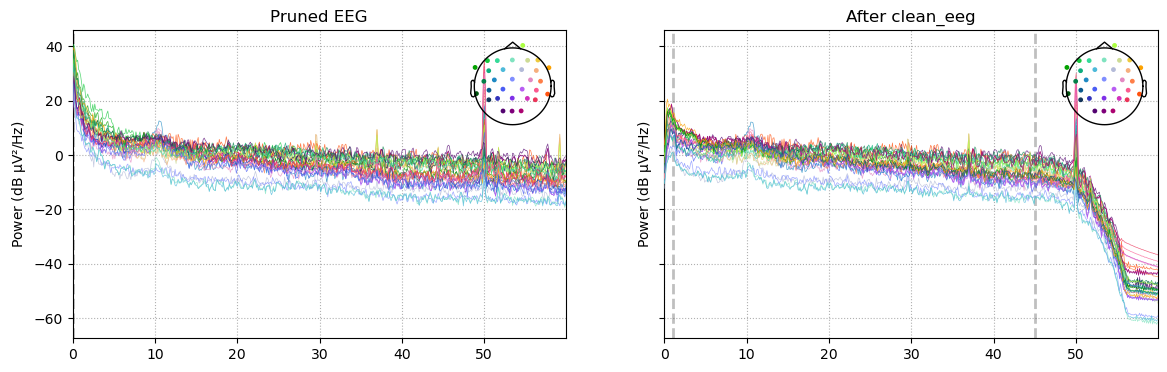

In [4]:
n_interpolated = len([ch for ch in bad.eeg if ch in run.eeg.ch_names])
eeg_clean = clean_eeg(run.eeg, n_interpolated, p.eeg)
print(f"Band {p.eeg.bandpass} Hz, ICA {p.eeg.ica_method} with {p.eeg.ica_n_components} "
      f"components ({n_interpolated} channels interpolated)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
run.eeg.compute_psd(picks="eeg", fmax=60, verbose=False).plot(axes=axes[0], show=False)
axes[0].set_title("Pruned EEG")
eeg_clean.compute_psd(picks="eeg", fmax=60, verbose=False).plot(axes=axes[1], show=False)
axes[1].set_title("After clean_eeg")
plt.show()

### Feature: alpha band power

Moving a hand weakens the alpha rhythm over the opposite motor cortex
(event-related desynchronisation), so the models see the EEG as alpha band power:
`band_power` band-passes each channel to the feature band, squares its Hilbert
envelope and brings it down to the fNIRS rate. The dashed lines mark the stimulus
window that step 3 cuts to.

Feature band (8.0, 12.0) Hz at 7.4 Hz: {'time': 1295, 'channel': 31}


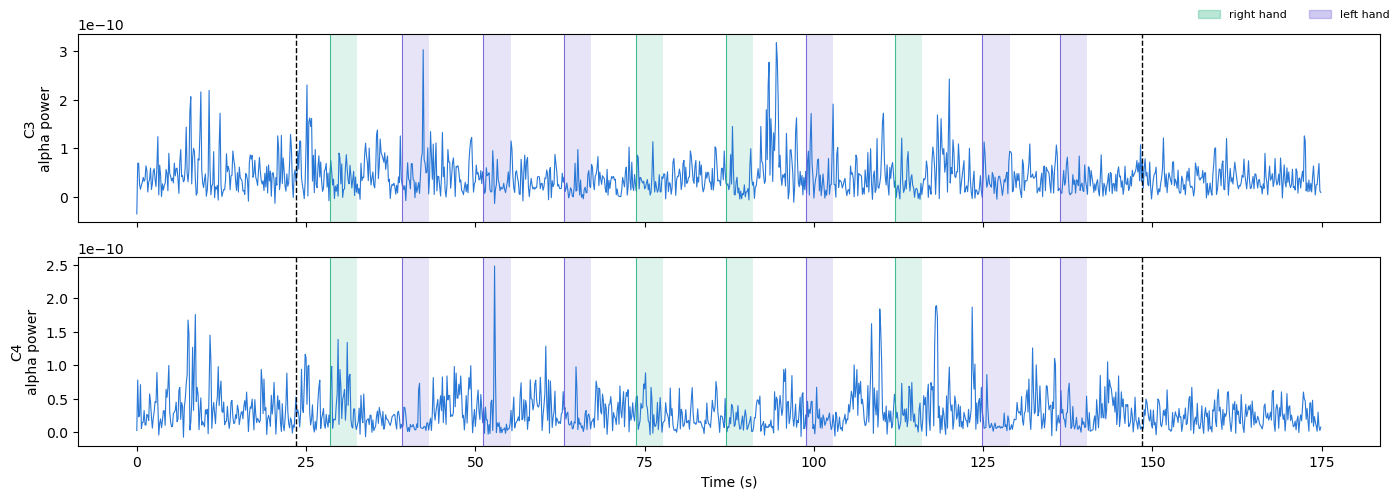

In [5]:
eeg_power = band_power(eeg_clean, p.eeg.feature_band, p.fnirs_srate, p.downsample_method)
print(f"Feature band {p.eeg.feature_band} Hz at {p.fnirs_srate} Hz: {dict(eeg_power.sizes)}")

fig, axes = plt.subplots(2, 1, figsize=(14, 5), sharex=True)
for ax, ch in zip(axes, ["C3", "C4"]):
    ax.plot(eeg_power.time, eeg_power.sel(channel=ch), lw=0.8, color=MODALITY["eeg"])
    shade_stimuli(ax, run.stim)
    for t in window:
        ax.axvline(t, color="k", ls="--", lw=1)
    ax.set_ylabel(f"{ch}\nalpha power")
axes[-1].set_xlabel("Time (s)")
stimulus_legend(fig, run.stim)
plt.tight_layout()
plt.show()

### mSPoC's feature: the band-passed EEG

mSPoC computes band power itself, so its preprocessing config
(`configs/preprocessing/mspoc.yaml`, `eeg_feature: bandpassed`) only band-passes the
EEG to the feature band and keeps its own rate. Ten seconds around the first trial:

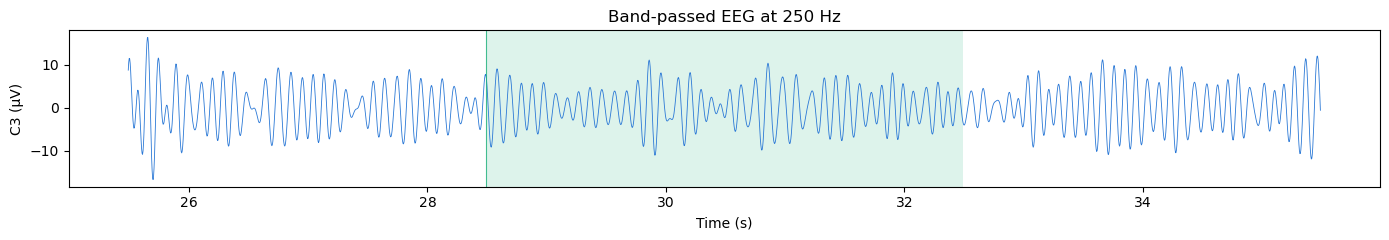

In [6]:
eeg_alpha = band_passed(eeg_clean, p.eeg.feature_band)
t0 = float(run.stim["onset"].iloc[0])
part = eeg_alpha.sel(time=slice(t0 - 3, t0 + 7))

fig, ax = plt.subplots(figsize=(14, 2.5))
ax.plot(part.time, part.sel(channel="C3") * 1e6, lw=0.6, color=MODALITY["eeg"])
shade_stimuli(ax, run.stim[run.stim["onset"].between(t0 - 3, t0 + 7)])
ax.set_ylabel("C3 (µV)")
ax.set_xlabel("Time (s)")
ax.set_title(f"Band-passed EEG at {eeg_clean.info['sfreq']:.0f} Hz")
plt.tight_layout()
plt.show()

## 2. fNIRS

### Optical density and motion correction

`motion_corrected_od` converts the amplitude to optical density (the change in light
absorption) and corrects motion artefacts with TDDR, then a wavelet filter. The plain
conversion is shown for comparison.

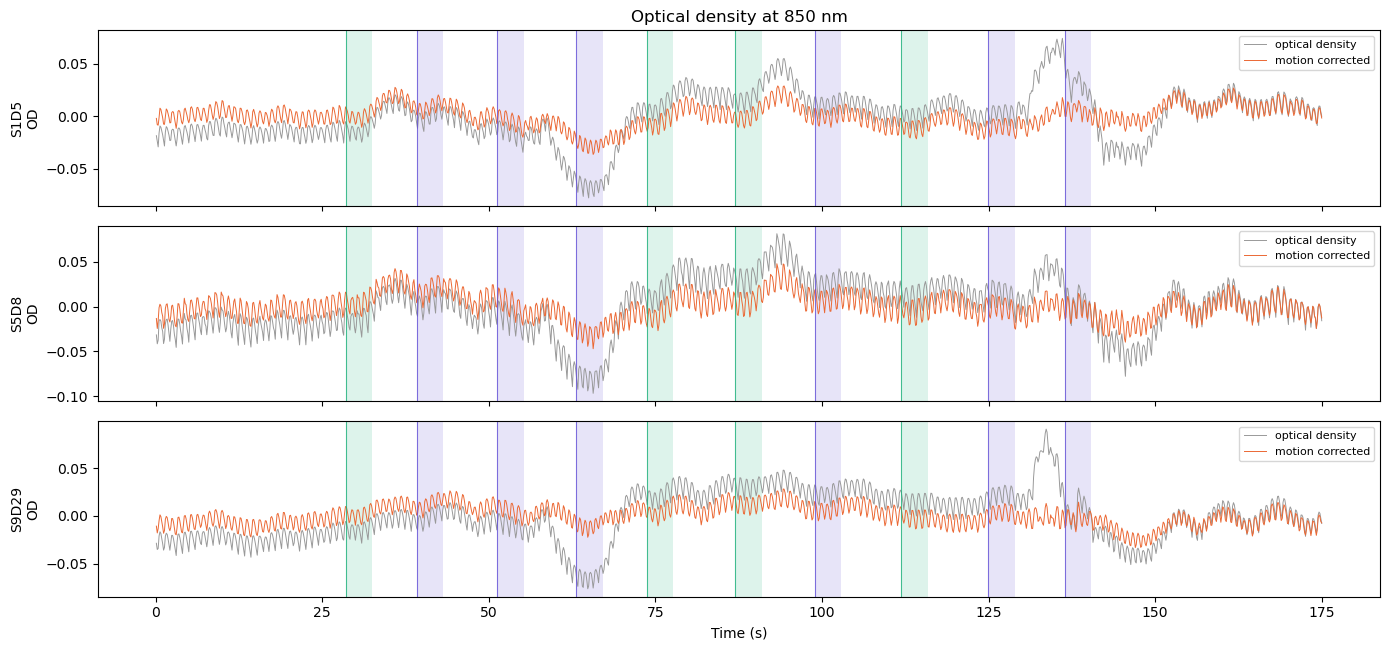

In [7]:
amp = run.fnirs
examples = list(amp.channel.values[:: max(1, amp.sizes["channel"] // 3)][:3])
od_plain = cw.int2od(amp)
od = motion_corrected_od(amp)
wl = amp.wavelength.values[-1]

fig, axes = plt.subplots(len(examples), 1, figsize=(14, 2.2 * len(examples)), sharex=True)
for ax, ch in zip(axes, examples):
    ax.plot(od_plain.time, od_plain.sel(channel=ch, wavelength=wl), lw=0.7, color="0.6",
            label="optical density")
    ax.plot(od.time, od.sel(channel=ch, wavelength=wl), lw=0.7, color=MODALITY["fnirs"],
            label="motion corrected")
    shade_stimuli(ax, run.stim)
    ax.set_ylabel(f"{ch}\nOD")
    ax.legend(loc="upper right", fontsize=8)
axes[0].set_title(f"Optical density at {wl:g} nm")
axes[-1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()

### HbO

`od_to_hbo` converts the two wavelengths to haemoglobin concentration (modified
Beer-Lambert law), keeps oxygenated haemoglobin (HbO) and band-passes it, which
removes slow drift and the heartbeat. The filters run on the whole recording, before
the cut, so the stimulus window (dashed) has no filter edge effects.

DPF 6.0, band (0.01, 0.6) Hz: {'time': 1295, 'channel': 104}


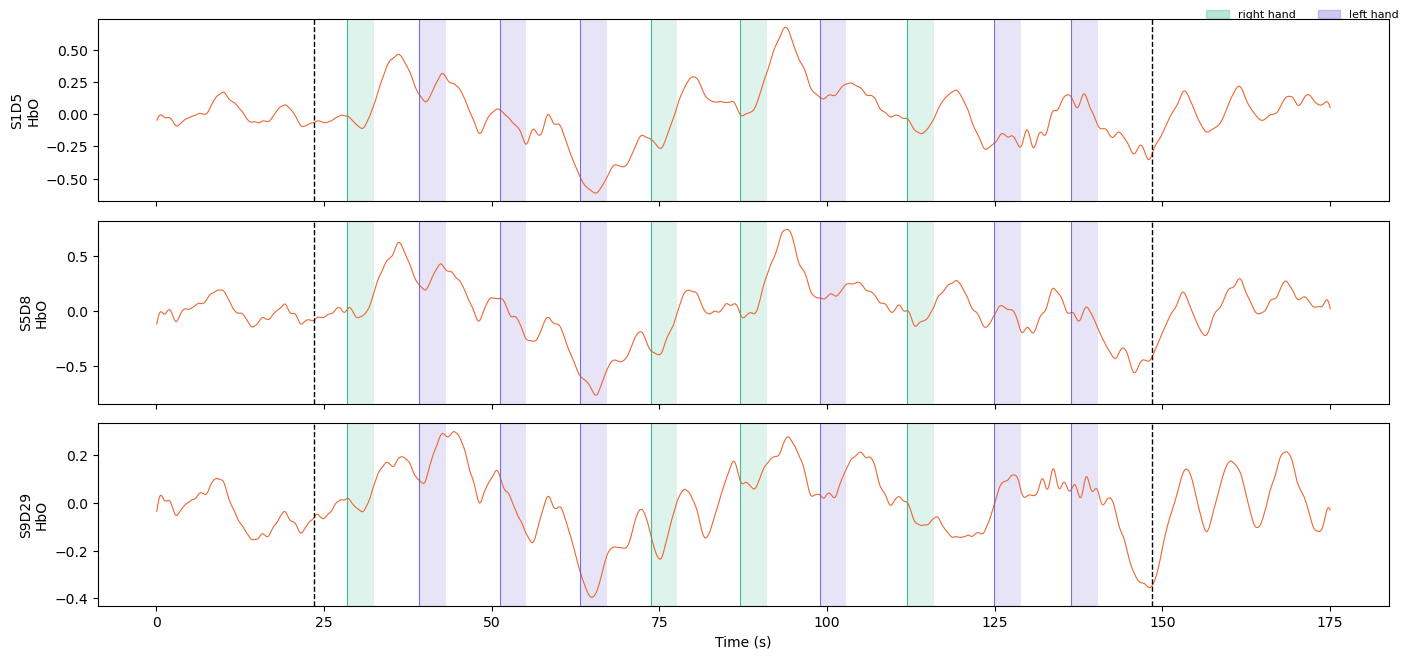

In [8]:
hbo = od_to_hbo(od, run.geo3d, p.fnirs)
print(f"DPF {p.fnirs.dpf}, band {p.fnirs.bandpass} Hz: {dict(hbo.sizes)}")

fig, axes = plt.subplots(len(examples), 1, figsize=(14, 2.2 * len(examples)), sharex=True)
for ax, ch in zip(axes, examples):
    ax.plot(hbo.time, hbo.sel(channel=ch), lw=0.8, color=MODALITY["fnirs"])
    shade_stimuli(ax, run.stim)
    for t in window:
        ax.axvline(t, color="k", ls="--", lw=1)
    ax.set_ylabel(f"{ch}\nHbO")
axes[-1].set_xlabel("Time (s)")
stimulus_legend(fig, run.stim)
plt.tight_layout()
plt.show()

## 3. One run, all steps

`preprocess_recording` runs all of the above and then:

- cuts both modalities to the **stimulus window** (a few seconds before the first
  trial to a few seconds after the last)
- puts them on **one time axis**: the EEG band power is interpolated onto the fNIRS
  samples
- **z-scores** every channel
- transforms the **ground truth** the same way, so it can be compared with what the
  models recover
- **checks** the alignment: a badly cut run stops the pipeline instead of producing
  quietly wrong results

`alignment_report` is the line the pipeline logs for each run.

In [9]:
pre = preprocess_recording(run, p)
print(alignment_report(pre))
print(f"EEG {dict(pre.eeg.sizes)}, fNIRS {dict(pre.fnirs.sizes)}")

sitting_post_rest_1/run_001_seed_2792333187: window 23.5-148.4 s · EEG 23.6-148.4 s (924) · fNIRS 23.6-148.4 s (924)
EEG {'time': 924, 'channel': 31}, fNIRS {'time': 924, 'channel': 104}


On synthetic data, each ground-truth source (black) can be compared with the channel
that matches it best. Both are z-scored; a negatively correlated channel is flipped.
Unmixing (notebook 04) combines all channels, which can recover a source better than
any single channel can; how well depends on the method.

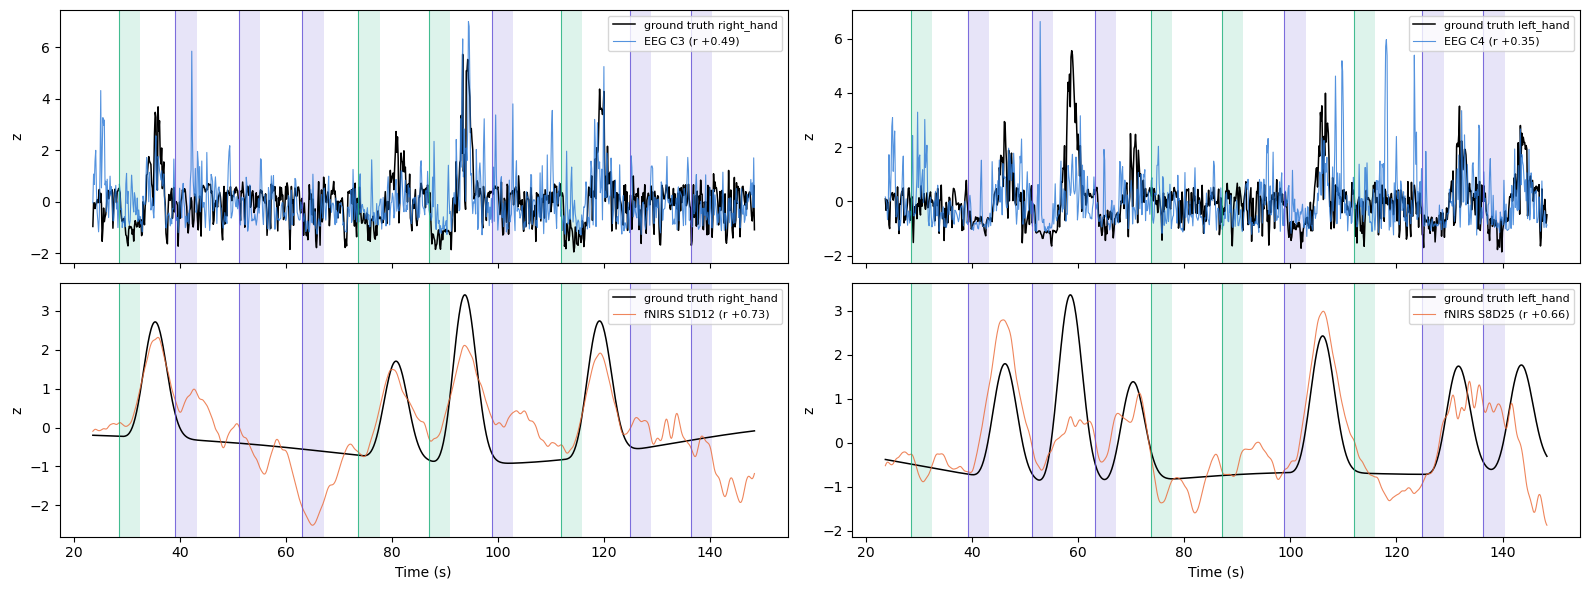

In [10]:
if pre.s_eeg is None or p.eeg_feature != "bandpower":
    print("No ground truth, or band-passed EEG: nothing to compare.")
else:
    sources = [str(s) for s in pre.s_eeg.source.values]
    fig, axes = plt.subplots(2, len(sources), figsize=(16, 6), sharex=True, squeeze=False)
    for col, src in enumerate(sources):
        for row, (truth, data, name) in enumerate([(pre.s_eeg, pre.eeg, "eeg"),
                                                   (pre.s_fnirs, pre.fnirs, "fnirs")]):
            ax = axes[row, col]
            s = truth.sel(source=src)
            ch, r = best_channel(s, data)
            ax.plot(s.time, s, color="k", lw=1.1, label=f"ground truth {src}")
            ax.plot(data.time, np.sign(r) * data.sel(channel=ch), color=MODALITY[name],
                    lw=0.8, alpha=0.8, label=f"{MODALITY_NAME[name]} {ch} (r {r:+.2f})")
            shade_stimuli(ax, pre.stim)
            ax.set_ylabel("z")
            ax.legend(loc="upper right", fontsize=8)
    for ax in axes[-1]:
        ax.set_xlabel("Time (s)")
    plt.tight_layout()
    plt.show()

## 4. Every run

`preprocess_recordings` does the same for every run. The result is the list of
`PreprocessedRecording` the unmixing step receives; `alignment_table` summarises how
each run was cut.

In [11]:
recordings = preprocess_recordings(pruned, p)
display(alignment_table(recordings))

,group,run,window_start,window_end,eeg_start,eeg_end,eeg_samples,fnirs_start,fnirs_end,fnirs_samples
0,sitting_post_rest_1,run_001_seed_2792333187,23.49,148.40,23.612604,148.372668,924,23.612604,148.372668,924
1,sitting_post_rest_1,run_002_seed_1570621782,23.76,137.48,23.882940,137.424060,841,23.882940,137.424060,841
2,sitting_post_rest_1,run_003_seed_492650652,21.42,144.78,21.449916,144.723132,913,21.449916,144.723132,913
3,sitting_post_rest_2,run_001_seed_2799647766,22.55,137.97,22.556049,137.854353,854,22.556049,137.854353,854
4,sitting_post_rest_2,run_002_seed_1777453137,22.84,150.28,22.961553,150.154641,942,22.961553,150.154641,942
5,sitting_post_rest_2,run_003_seed_730335040,24.86,150.81,24.989073,150.695313,931,24.989073,150.695313,931
6,sitting_pre_rest_1,run_001_seed_2418716002,22.37,142.71,22.418030,142.582382,890,22.418030,142.582382,890
7,sitting_pre_rest_1,run_002_seed_1946698139,21.02,145.73,21.066350,145.691246,923,21.066350,145.691246,923
8,sitting_pre_rest_1,run_003_seed_2902985657,21.88,140.29,22.012526,140.284526,876,22.012526,140.284526,876
9,sitting_pre_rest_2,run_001_seed_4057827324,24.38,139.97,24.445109,139.878581,855,24.445109,139.878581,855


`plot_inputs` draws a few channels of each modality, run after run, as the models
see them. The test group's runs:

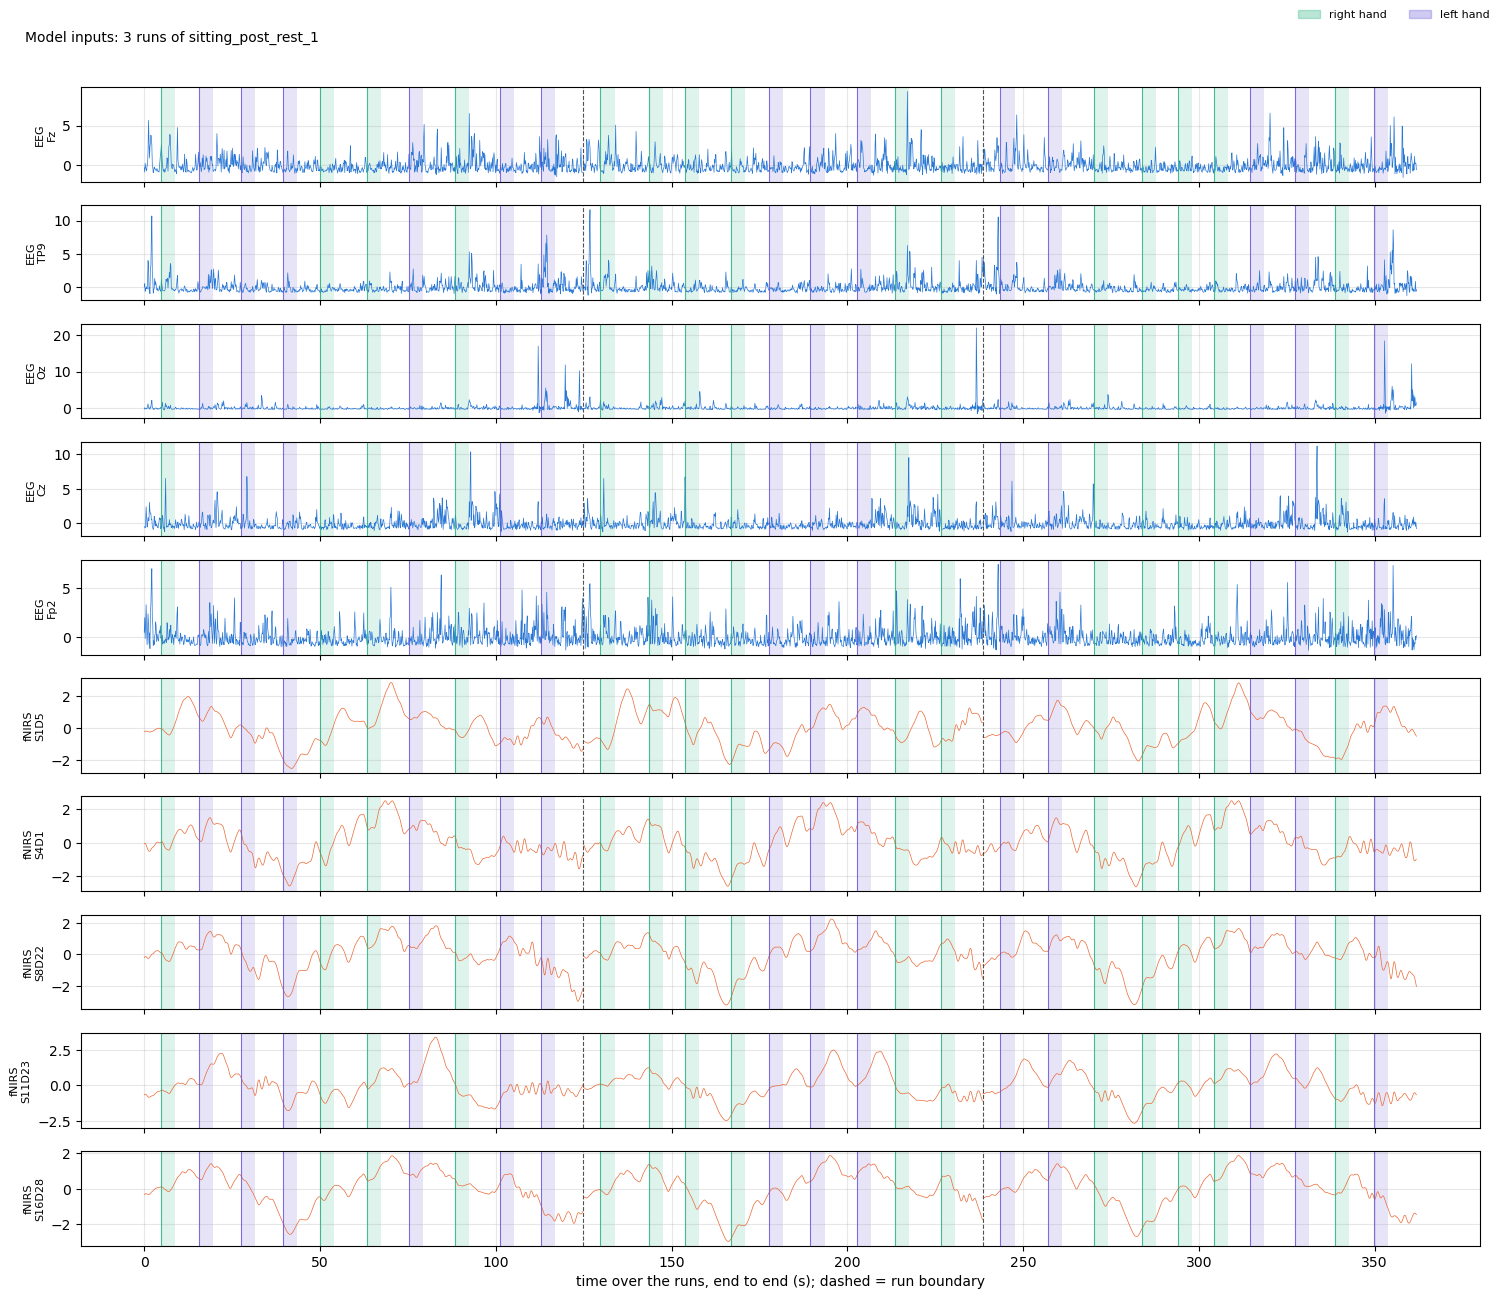

In [12]:
fig = plot_inputs(recordings, groups=[subject.test_group])
plt.show()

## Changing the preprocessing

Every value above comes from the preprocessing config. To change the feature band,
the filters or the ICA, copy `configs/preprocessing/full_recording.yaml`, edit it, and
point the experiment's `preprocessing:` at the copy. A new processing step goes into
`preprocess_recording` in `src/preprocessing/preprocess.py`.

In [13]:
print(as_yaml(p))

eeg_feature: bandpower
fnirs_srate: 7.4
downsample_method: resample
trim_pre_sec: 5.0
trim_post_sec: 8.0
fnirs_mspoc_srate: null
eeg:
  bandpass:
  - 1.0
  - 45.0
  ica_n_components: 15
  ica_method: picard
  random_state: 42
  feature_band:
  - 8.0
  - 12.0
  drop_interpolated: false
fnirs:
  dpf: 6.0
  bandpass:
  - 0.01
  - 0.6
checks:
  min_window_coverage: 0.9



## Next

Notebook 04 fits the CCA-family models to these runs.